# 02 - Model evaluation

Compares the tuned **Random Forest** and **XGBoost** models: test-set metrics, cross-validation, prediction errors and feature importance.

Before running, train the models from the project root:
```
python -m src.tune
python -m src.train
```

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # so we can import from src/

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedKFold, cross_validate

from src.config import ALL_FEATURES, LOG_TARGET, MODELS_DIR, RANDOM_STATE, TARGET, USE_EXTRA_FEATURES
from src.data_preprocessing import load_data, split_data
from src.evaluate import evaluate_model
from src.pipeline import build_pipeline
from src.train import get_models

sns.set_theme(style="whitegrid")
LABELS = {"random_forest": "Random Forest", "xgboost": "XGBoost"}

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)   # same split as in train.py
models = {n: joblib.load(MODELS_DIR / f"{n}.joblib") for n in LABELS}
print(f"train: {len(X_train)} rows, test: {len(X_test)} rows")

c:\Users\svitj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator OrdinalEncoder from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\svitj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\svitj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimato

train: 436 rows, test: 109 rows


c:\Users\svitj\AppData\Local\Programs\Python\Python313\Lib\pickle.py:1760: UserWarning: [12:35:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


## 1. Test-set metrics

These models were trained on the train split only, so the test split is unseen data. It has just ~109 houses, so these numbers are noisy - compare with the cross-validation below.

In [2]:
rows = []
for name, model in models.items():
    rows.append({"model": LABELS[name], **evaluate_model(model, X_test, y_test)})
metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics

,mae,rmse,r2
model,,,
Random Forest,1030952.426,1409621.649,0.607
XGBoost,965818.562,1333775.969,0.648


## 2. Cross-validation (more reliable)

Repeated 5-fold CV (3 repeats) on the whole dataset. Note: hyperparameters were tuned on the train split, so these scores are slightly optimistic, but the comparison between models stays fair.

In [3]:
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, model in get_models().items():
    pipe = build_pipeline(model, USE_EXTRA_FEATURES, LOG_TARGET)
    res = cross_validate(pipe, df[ALL_FEATURES], df[TARGET], cv=cv, scoring=scoring)
    rows.append({
        "model": LABELS[name],
        "R2 mean": res["test_r2"].mean(), "R2 std": res["test_r2"].std(),
        "MAE": -res["test_mae"].mean(), "RMSE": -res["test_rmse"].mean(),
    })
pd.DataFrame(rows).set_index("model").round(3)

Using tuned hyperparameters from best_params.json



,R2 mean,R2 std,MAE,RMSE
model,,,,
Random Forest,0.647,0.036,782956.274,1096514.152
XGBoost,0.649,0.041,786804.508,1090379.304


## 3. Actual vs predicted

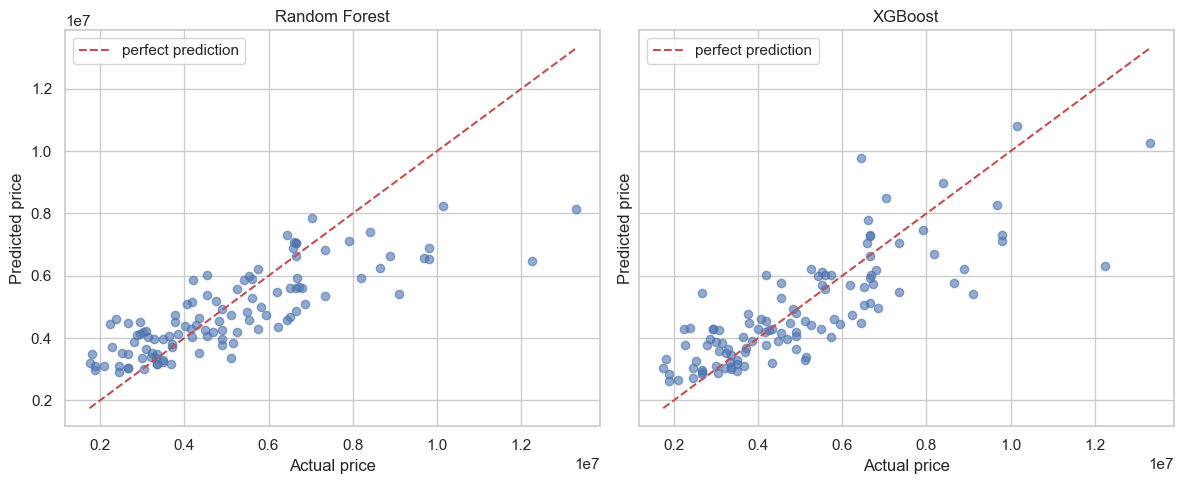

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.6)
    lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lim, lim, "r--", label="perfect prediction")
    ax.set_title(LABELS[name]); ax.set_xlabel("Actual price"); ax.set_ylabel("Predicted price")
    ax.legend()
plt.tight_layout(); plt.show()

## 4. Residuals

Residual = actual - predicted. Ideally they are centred on 0 with no pattern. A funnel shape (errors growing with price) means the model is less accurate for expensive houses.

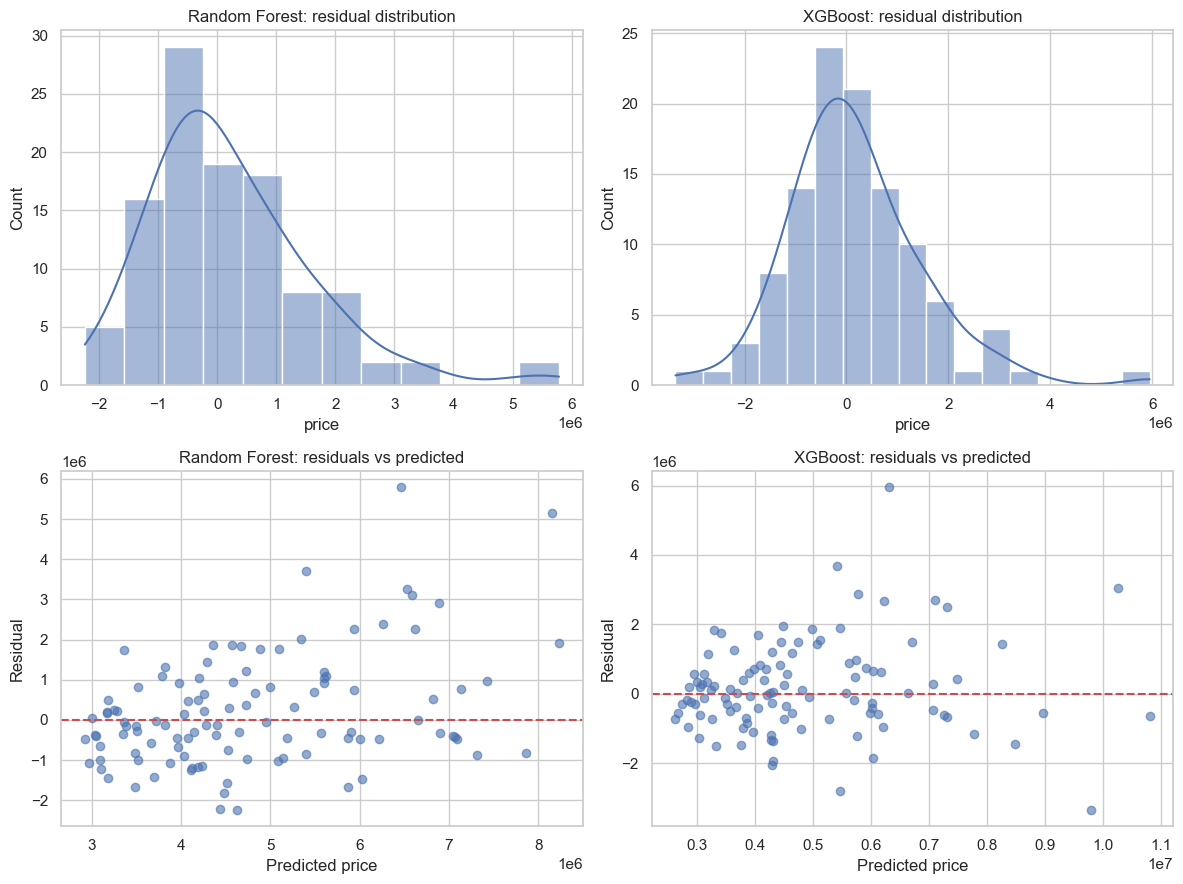

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, (name, model) in enumerate(models.items()):
    pred = model.predict(X_test)
    resid = y_test - pred
    sns.histplot(resid, kde=True, ax=axes[0, col]).set_title(f"{LABELS[name]}: residual distribution")
    axes[1, col].scatter(pred, resid, alpha=0.6)
    axes[1, col].axhline(0, color="r", ls="--")
    axes[1, col].set_title(f"{LABELS[name]}: residuals vs predicted")
    axes[1, col].set_xlabel("Predicted price"); axes[1, col].set_ylabel("Residual")
plt.tight_layout(); plt.show()

## 5. Feature importance

**Built-in importance** (how much each encoded column is used inside the trees). It is biased toward continuous features such as `area`.

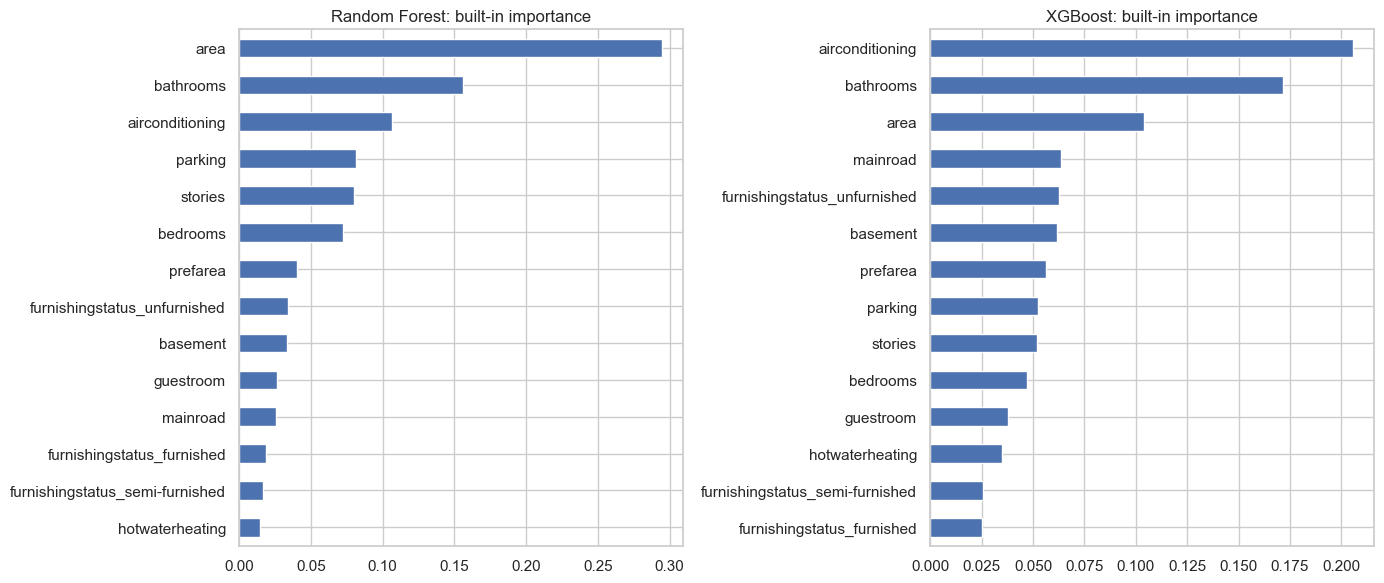

In [6]:
def inner_pipeline(model):
    # With LOG_TARGET=True the pipeline is wrapped in TransformedTargetRegressor
    return model.regressor_ if hasattr(model, "regressor_") else model

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, model) in zip(axes, models.items()):
    pipe = inner_pipeline(model)
    names = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values()
    imp.plot.barh(ax=ax)
    ax.set_title(f"{LABELS[name]}: built-in importance")
plt.tight_layout(); plt.show()

**Permutation importance** (on the test set): how much R² drops when one original feature is shuffled. It works the same way for both models and treats `furnishingstatus` as a single feature, so it is the more trustworthy view.

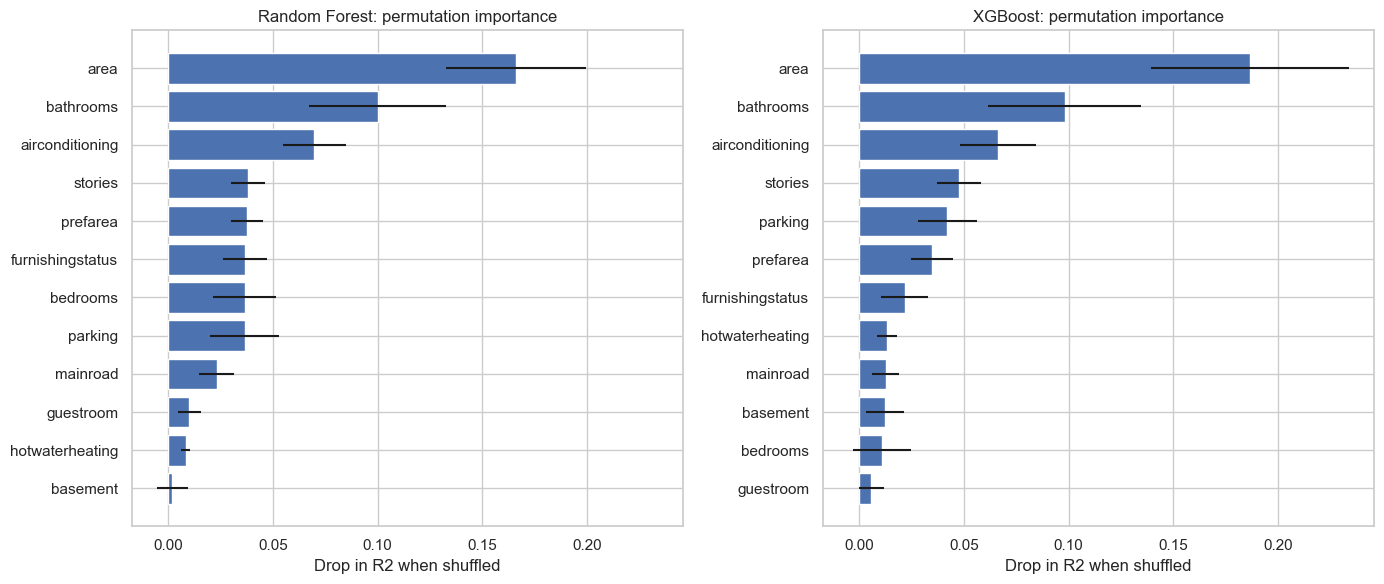

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, (name, model) in zip(axes, models.items()):
    r = permutation_importance(model, X_test, y_test, n_repeats=20,
                               random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
    imp = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std},
                       index=X_test.columns).sort_values("mean")
    ax.barh(imp.index, imp["mean"], xerr=imp["std"])
    ax.set_title(f"{LABELS[name]}: permutation importance")
    ax.set_xlabel("Drop in R2 when shuffled")
plt.tight_layout(); plt.show()

## 6. Conclusions

- Both models reach R2 of about 0.65: the dataset (545 rows, 12 features) limits what any model can explain, and tuning or extra features did not change this meaningfully (see `src/experiments.py`).
- XGBoost scored higher on the test split, but in cross-validation the two models are close, so the difference is small relative to the fold-to-fold noise.
- Add your own observations here after looking at the plots above: which features matter most, whether errors grow for expensive houses, and where the models disagree.